# Computer Vision Lab 07 — Solutions


In [ ]:
from pathlib import Path
import urllib.request
import json
import cv2
import numpy as np
import matplotlib.pyplot as plt

DATA = Path("lab07_data")
RESULTS = Path("lab07_results")
DATA.mkdir(exist_ok=True)
RESULTS.mkdir(exist_ok=True)
np.set_printoptions(precision=3, suppress=True)

def download(url, path):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    if not path.exists():
        urllib.request.urlretrieve(url, path)
    return path

def show_images(images, titles):
    fig, axes = plt.subplots(1, len(images), figsize=(5 * len(images), 4))
    for ax, image, title in zip(np.atleast_1d(axes), images, titles):
        if image.ndim == 3:
            image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        ax.imshow(image, cmap="gray")
        ax.set_title(title)
        ax.axis("off")
    plt.tight_layout()
    plt.show()

## Q1(a) — 2D transformations
Use a public OpenCV image. Translation moves it, rotation turns it, scaling changes its size, and shearing slants it. A fixed-size canvas makes the size and position changes easy to compare.

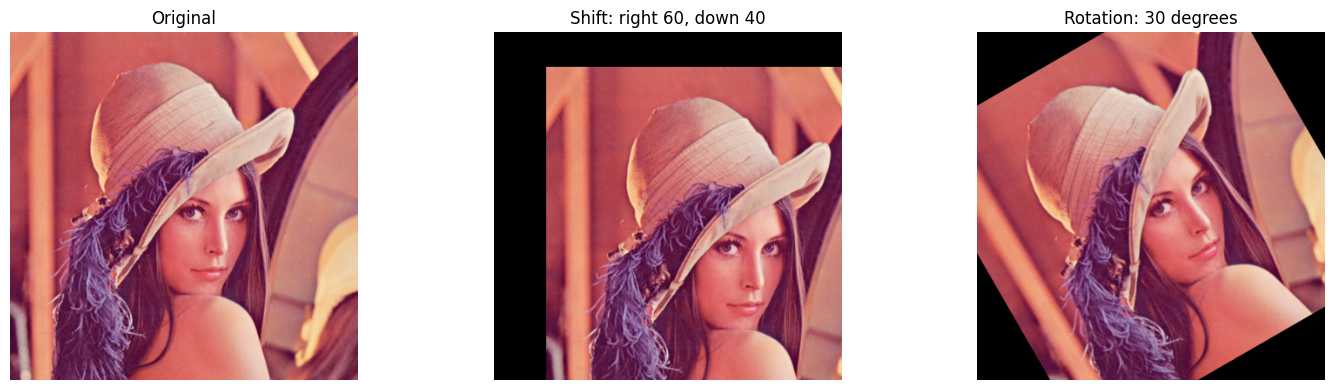

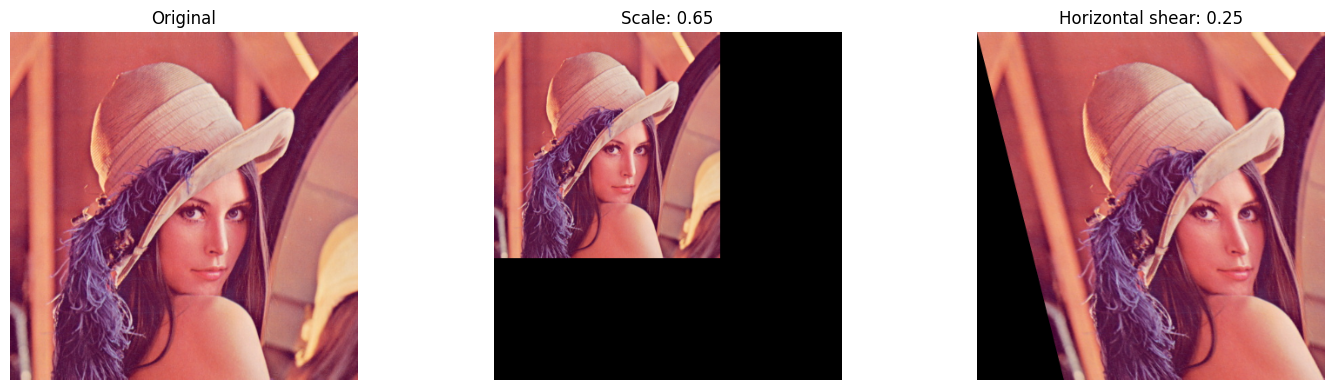

In [ ]:
base_url = "https://raw.githubusercontent.com/opencv/opencv/4.12.0/samples/data/"
image_path = download(base_url + "lena.jpg", DATA / "lena.jpg")
img = cv2.imread(str(image_path))
img = cv2.resize(img, (400, 400))
h, w = img.shape[:2]

translation = np.float32([[1, 0, 60], [0, 1, 40]])
rotation = cv2.getRotationMatrix2D((w / 2, h / 2), 30, 1)
shearing = np.float32([[1, 0.25, 0], [0, 1, 0]])

translated = cv2.warpAffine(img, translation, (w, h))
rotated = cv2.warpAffine(img, rotation, (w, h))
sheared = cv2.warpAffine(img, shearing, (w, h))
small = cv2.resize(img, None, fx=0.65, fy=0.65)
scaled = np.zeros_like(img)
scaled[:small.shape[0], :small.shape[1]] = small

show_images([img, translated, rotated], ["Original", "Shift: right 60, down 40", "Rotation: 30 degrees"])
show_images([img, scaled, sheared], ["Original", "Scale: 0.65", "Horizontal shear: 0.25"])

**Observation:** translation changes location without changing size. Rotation changes orientation; scaling reduces both dimensions to 65%. Shearing shifts rows by different amounts. Black areas are outside the source image, and some content is clipped by the fixed canvas.

## Q1(b) — 3D transformation
Rotate a cube around all three axes, then move it by `(2, 1, 1)`. The rotation order is x, then y, then z. The same cube edges are used before and after transformation.

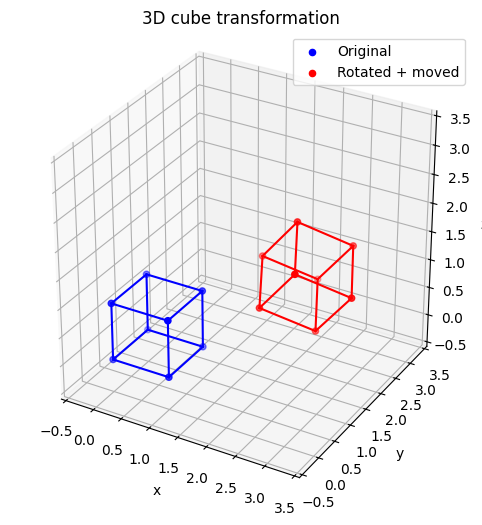

First vertex before: [0. 0. 0.] after: [2. 1. 1.]


In [ ]:
cube = np.float64([[0,0,0], [1,0,0], [1,1,0], [0,1,0],
                   [0,0,1], [1,0,1], [1,1,1], [0,1,1]])
edges = [(0,1),(1,2),(2,3),(3,0),(4,5),(5,6),(6,7),(7,4),
         (0,4),(1,5),(2,6),(3,7)]
a, b, g = np.deg2rad([25, 30, 40])
Rx = np.array([[1,0,0], [0,np.cos(a),-np.sin(a)], [0,np.sin(a),np.cos(a)]])
Ry = np.array([[np.cos(b),0,np.sin(b)], [0,1,0], [-np.sin(b),0,np.cos(b)]])
Rz = np.array([[np.cos(g),-np.sin(g),0], [np.sin(g),np.cos(g),0], [0,0,1]])
R = Rz @ Ry @ Rx
moved_cube = (R @ cube.T).T + [2, 1, 1]

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection="3d")
for vertices, color, label in [(cube, "blue", "Original"), (moved_cube, "red", "Rotated + moved")]:
    for i, j in edges:
        ax.plot(*vertices[[i,j]].T, color=color)
    ax.scatter(*vertices.T, color=color, label=label)
ax.set(xlabel="x", ylabel="y", zlabel="z", title="3D cube transformation")
ax.set_xlim(-0.5, 3.5); ax.set_ylim(-0.5, 3.5); ax.set_zlim(-0.5, 3.5)
ax.set_box_aspect((1, 1, 1))
ax.legend()
plt.show()
print("First vertex before:", cube[0], "after:", moved_cube[0])

**Observation:** the cube changes orientation and position in x, y, and z. Its edge lengths stay the same because rotation and translation do not change size.

## Q1(c) — Homogeneous coordinates
A 2D point `(x, y)` becomes `(x, y, 1)`. With the extra coordinate, translation can be written as matrix multiplication, just like rotation and scaling. Several transformations can then be combined by multiplying matrices. For a general homogeneous point `(X, Y, W)`, recover the ordinary point as `(X/W, Y/W)` when `W != 0`.

In [ ]:
point = np.array([2, 3, 1])
T = np.array([[1, 0, 5], [0, 1, 4], [0, 0, 1]])
new_point = T @ point
print("Homogeneous point:", point)
print("After translation:", new_point)
print("2D point:", new_point[:2] / new_point[2])

Homogeneous point: [2 3 1]
After translation: [7 7 1]
2D point: [7. 7.]


## Q1(d) — Affine transformation
Three non-collinear corresponding points define an affine transformation. Straight lines remain straight and parallel lines remain parallel. **A rectangle can become a parallelogram**; right angles and lengths are generally not preserved.

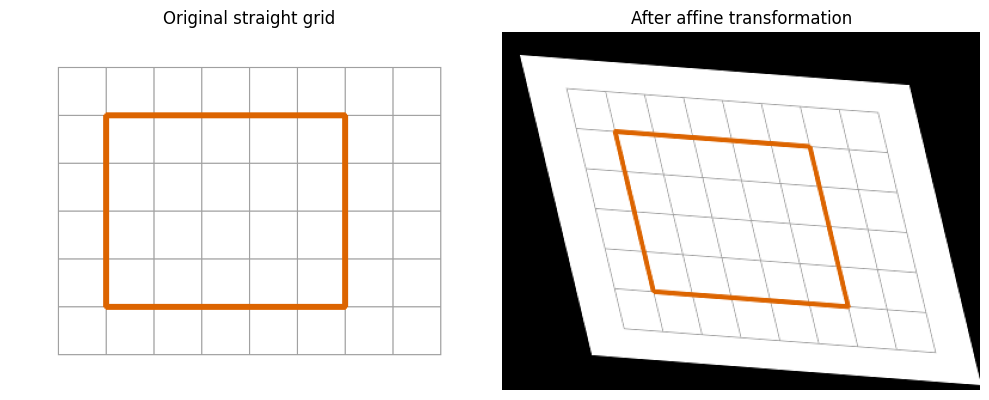

Affine matrix:
 [[ 0.815  0.201 15.   ]
 [ 0.063  0.836 20.   ]]


In [ ]:
grid = np.full((300, 400, 3), 255, np.uint8)
for x in range(40, 361, 40):
    cv2.line(grid, (x, 30), (x, 270), (160, 160, 160), 1)
for y in range(30, 271, 40):
    cv2.line(grid, (40, y), (360, y), (160, 160, 160), 1)
cv2.rectangle(grid, (80, 70), (280, 230), (0, 100, 220), 3)
source = np.float32([[0,0], [399,0], [0,299]])
destination = np.float32([[15,20], [340,45], [75,270]])
A = cv2.getAffineTransform(source, destination)
affine_img = cv2.warpAffine(grid, A, (400, 300))
show_images([grid, affine_img], ["Original straight grid", "After affine transformation"])
print("Affine matrix:\n", A)

## Q1(e) — Projective transformation (homography)
Create a simple document, tilt it using a homography, then correct the tilted view. This controlled example gives us exact corner positions. A real photograph works the same way after selecting its four document corners.

Corner order throughout: **top-left, top-right, bottom-right, bottom-left**.

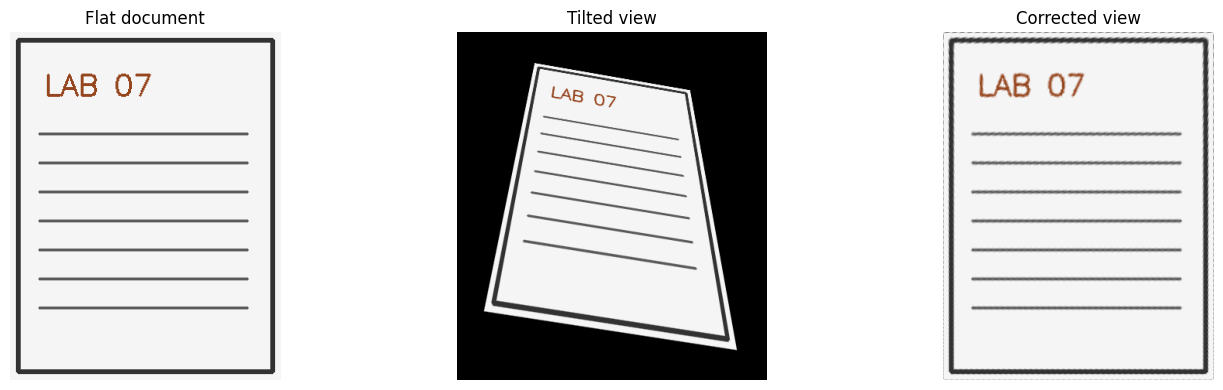

In [ ]:
document = np.full((360, 280, 3), 245, np.uint8)
cv2.rectangle(document, (8, 8), (271, 351), (50, 50, 50), 3)
cv2.putText(document, "LAB 07", (35, 65), cv2.FONT_HERSHEY_SIMPLEX, 1, (30, 70, 150), 2)
for y in range(105, 310, 30):
    cv2.line(document, (30, y), (245, y), (90, 90, 90), 2)

rectangle = np.float32([[0,0], [279,0], [279,359], [0,359]])
tilted_corners = np.float32([[100,40], [300,75], [360,410], [35,360]])
H_tilt = cv2.getPerspectiveTransform(rectangle, tilted_corners)
tilted = cv2.warpPerspective(document, H_tilt, (400, 450))
H_correct = cv2.getPerspectiveTransform(tilted_corners, rectangle)
corrected = cv2.warpPerspective(tilted, H_correct, (280, 360))
show_images([document, tilted, corrected], ["Flat document", "Tilted view", "Corrected view"])

**Observation:** the homography maps a quadrilateral to a rectangle, making the page look front-facing. The second warp introduces some interpolation blur, so the corrected pixels need not exactly equal the original pixels.

## Q2 — Perspective correction (unwarping)
Use the manual's `apply_perspective_transform` function with the **tilted corners as source** and the **rectangle as destination**. This reverses the forward tilt; do not swap image width and height in `warpPerspective`.

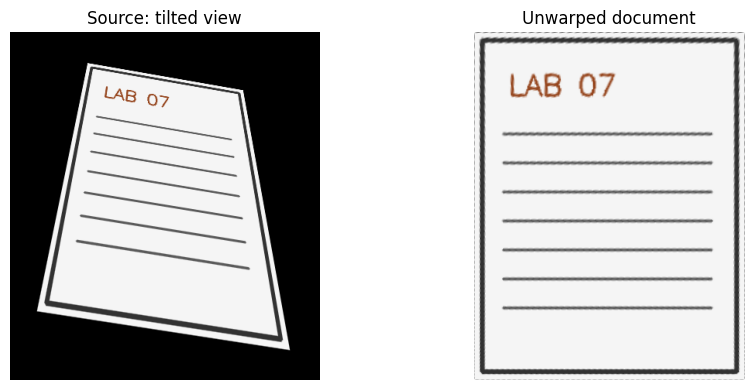

Inverse homography:
 [[   1.38     0.28  -149.186]
 [  -0.321    1.834  -41.258]
 [  -0.       0.002    1.   ]]
Inverse × forward (normalized):
 [[ 1. -0.  0.]
 [ 0.  1.  0.]
 [-0. -0.  1.]]


In [ ]:
def apply_perspective_transform(original_img, h_dim, w_dim, source_points, dest_points, title):
    M = cv2.getPerspectiveTransform(np.float32(source_points), np.float32(dest_points))
    result = cv2.warpPerspective(original_img, M, (w_dim, h_dim))
    show_images([original_img, result], ["Source: tilted view", title])
    return result, M

unwarped, H_inverse = apply_perspective_transform(
    tilted, 360, 280, tilted_corners, rectangle, "Unwarped document")
cv2.imwrite(str(RESULTS / "unwarped_document.png"), unwarped)
print("Inverse homography:\n", H_inverse)
# Multiplication gives identity up to a nonzero scale.
identity = H_inverse @ H_tilt
identity = identity / identity[2, 2]
print("Inverse × forward (normalized):\n", identity)
assert np.allclose(identity, np.eye(3), atol=1e-5)

**Answer:** unwarping restores a rectangular view by reversing the corner mapping. The normalized inverse-times-forward matrix is the identity, confirming the geometry.

## Q3 — Calibrate once, save parameters, undistort frames
Use 13 public OpenCV checkerboard photos from the same sample camera. The board has **9 × 6 inner corners**. A square size of 1 gives translation in board-square units; the physical square size is not supplied.

The manual's workflow is retained: detect corners, refine them, calibrate, measure reprojection error, save, reload, and undistort. These parameters must **not** be used to correct a different physical camera.

In [ ]:
calibration_dir = DATA / "calibration"
for number in [1,2,3,4,5,6,7,8,9,11,12,13,14]:
    name = f"left{number:02d}.jpg"
    download(base_url + name, calibration_dir / name)
print("Downloaded calibration photos:", len(list(calibration_dir.glob("*.jpg"))))

Downloaded calibration photos: 13


Successful views: 13
Camera matrix:
 [[536.073   0.    342.37 ]
 [  0.    536.016 235.537]
 [  0.      0.      1.   ]]
Distortion coefficients: [-0.265 -0.047  0.002 -0.     0.252]
Calibration RMS: 0.4087 pixels
Mean point reprojection error: 0.2346 pixels


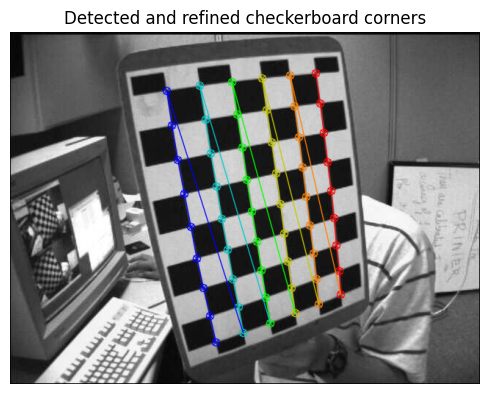

In [ ]:
def calibrate_camera(image_dir, save_path, board=(9, 6)):
    object_grid = np.zeros((board[0] * board[1], 3), np.float32)
    object_grid[:, :2] = np.mgrid[0:board[0], 0:board[1]].T.reshape(-1, 2)
    object_points, image_points = [], []
    image_size = None
    criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 30, 0.001)
    for path in sorted(Path(image_dir).glob("*.jpg")):
        image = cv2.imread(str(path))
        if image is None:
            continue
        gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
        size = gray.shape[::-1]
        if image_size is not None and size != image_size:
            raise ValueError("All calibration photos must have the same resolution.")
        image_size = size
        found, corners = cv2.findChessboardCorners(gray, board)
        if found:
            corners = cv2.cornerSubPix(gray, corners, (11,11), (-1,-1), criteria)
            object_points.append(object_grid.copy())
            image_points.append(corners)
            example = image.copy()
            cv2.drawChessboardCorners(example, board, corners, found)
    if len(object_points) < 10:
        raise ValueError("At least 10 successful checkerboard views are required.")
    rms, K, dist, rvecs, tvecs = cv2.calibrateCamera(
        object_points, image_points, image_size, None, None)
    errors = []
    for obj, observed, rvec, tvec in zip(object_points, image_points, rvecs, tvecs):
        projected, _ = cv2.projectPoints(obj, rvec, tvec, K, dist)
        errors.extend(np.linalg.norm(observed.reshape(-1,2) - projected.reshape(-1,2), axis=1))
    np.savez(save_path, K=K, dist=dist, image_size=image_size,
             rvecs=np.array(rvecs), tvecs=np.array(tvecs),
             rms=rms, mean_error=np.mean(errors))
    print("Successful views:", len(object_points))
    print("Camera matrix:\n", K)
    print("Distortion coefficients:", dist.ravel())
    print(f"Calibration RMS: {rms:.4f} pixels")
    print(f"Mean point reprojection error: {np.mean(errors):.4f} pixels")
    show_images([example], ["Detected and refined checkerboard corners"])

calibration_file = RESULTS / "camera_calibration.npz"
# Calibrate once; future runs reuse the saved values.
if not calibration_file.exists():
    calibrate_camera(calibration_dir, calibration_file)
else:
    print("Reusing saved calibration:", calibration_file)
    saved = np.load(calibration_file)
    print("K:\n", saved["K"])
    print("Mean error:", float(saved["mean_error"]), "pixels")

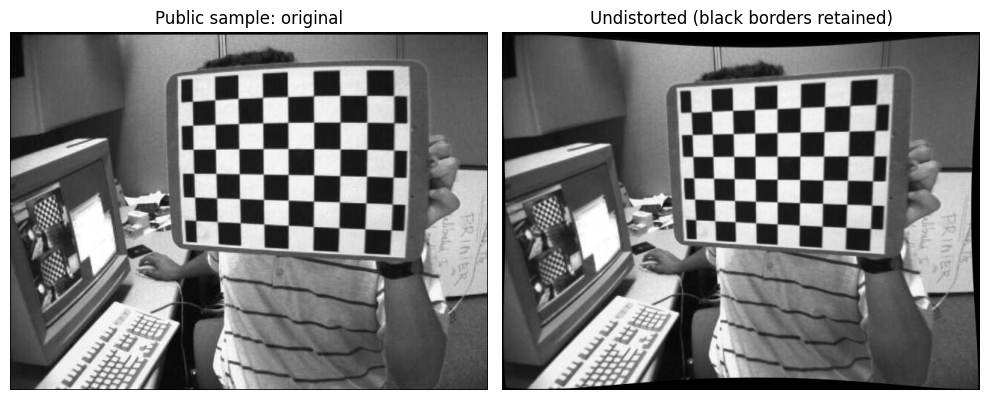

True

In [ ]:
cal = np.load(calibration_file)
K, dist = cal["K"], cal["dist"]
frame = cv2.imread(str(calibration_dir / "left01.jpg"))
h_frame, w_frame = frame.shape[:2]
new_K, roi = cv2.getOptimalNewCameraMatrix(K, dist, (w_frame,h_frame), 1, (w_frame,h_frame))
undistorted = cv2.undistort(frame, K, dist, None, new_K)
show_images([frame, undistorted], ["Public sample: original", "Undistorted (black borders retained)"])
cv2.imwrite(str(RESULTS / "undistorted_sample.png"), undistorted)

### Live-feed implementation — definition only
The following function implements `VideoCapture` → `undistort` → display, as requested in the sheet. **It is not called anywhere in this notebook**, so running all cells does not access a camera. The executed demonstration above uses a downloaded still frame.

For a separately authorized live experiment, first calibrate that actual camera using its own checkerboard photos and pass that calibration file. The function requires the calibrated resolution and stops after a fixed time or the Q key.

In [ ]:
def undistort_live_camera(own_camera_calibration, camera_index=0, max_seconds=30):
    import time
    calibration = np.load(own_camera_calibration)
    K, dist = calibration["K"], calibration["dist"]
    width, height = map(int, calibration["image_size"])
    cap = cv2.VideoCapture(camera_index)
    try:
        if not cap.isOpened():
            raise RuntimeError("Camera could not be opened.")
        cap.set(cv2.CAP_PROP_FRAME_WIDTH, width)
        cap.set(cv2.CAP_PROP_FRAME_HEIGHT, height)
        start = time.monotonic()
        while time.monotonic() - start < max_seconds:
            ok, frame = cap.read()
            if not ok:
                break
            if frame.shape[1::-1] != (width, height):
                raise ValueError("Frame resolution differs from the calibration resolution.")
            corrected = cv2.undistort(frame, K, dist)
            cv2.imshow("Original | Undistorted (Q to stop)", np.hstack([frame, corrected]))
            if cv2.waitKey(1) & 0xFF == ord("q"):
                break
    finally:
        cap.release()
        cv2.destroyAllWindows()

print("Live-feed function defined only. No camera has been opened.")

Live-feed function defined only. No camera has been opened.


**Observation:** calibration estimates focal lengths, principal point, and distortion coefficients. Undistortion straightens lens-induced curvature. Reprojection error measures agreement with detected corners; it is an in-sample check, not proof of accuracy on a new camera.

## Q4 — Build a 3D scene using COLMAP
Use the public **Sceaux Castle** photo set, photographed by **Pierre Moulon (copyright 2012)** and published by openMVG. Download its 11 views and resize each to a maximum width of 1200 pixels to keep processing manageable.

The image set is used as input to **COLMAP via PyCOLMAP**, not to openMVG's reconstruction software. COLMAP detects SIFT features, matches them across images, estimates camera poses, and triangulates 3D points. SciPy then triangulates the main facade to make a **coarse mesh from the sparse cloud**. This is a simple CPU demonstration, not a dense multi-view stereo reconstruction.

Multi-view photos: 11


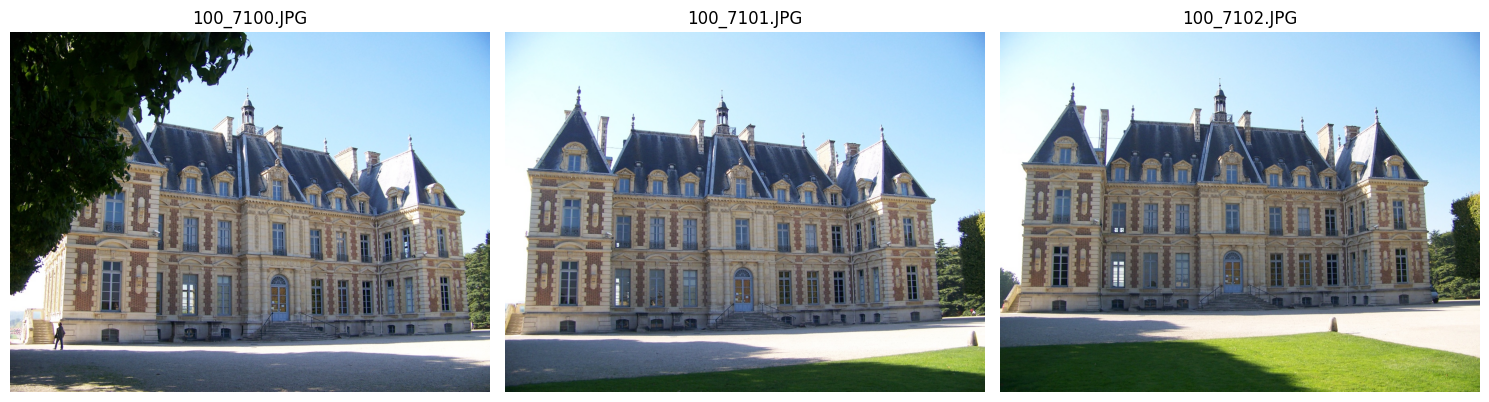

In [ ]:
scene_dir = DATA / "scene"
scene_dir.mkdir(exist_ok=True)
repository = "https://api.github.com/repos/openMVG/ImageDataset_SceauxCastle/contents/images"
# Query GitHub only if no scene images have been downloaded yet.
if len(list(scene_dir.glob("*.JPG"))) < 11:
    with urllib.request.urlopen(repository) as response:
        files = json.load(response)
    for item in files:
        if item["name"].lower().endswith(".jpg"):
            path = download(item["download_url"], scene_dir / item["name"])
            image = cv2.imread(str(path))
            height, width = image.shape[:2]
            if width > 1200:
                image = cv2.resize(image, (1200, round(height * 1200 / width)))
                cv2.imwrite(str(path), image)
scene_photos = sorted(scene_dir.glob("*.JPG"))
print("Multi-view photos:", len(scene_photos))
show_images([cv2.imread(str(p)) for p in scene_photos[:3]], [p.name for p in scene_photos[:3]])

In [ ]:
import pycolmap

colmap_dir = RESULTS / "colmap"
colmap_dir.mkdir(exist_ok=True)
model_dir = colmap_dir / "model"
database = colmap_dir / "database.db"
if (model_dir / "cameras.bin").exists():
    model = pycolmap.Reconstruction(model_dir)
else:
    # 1. Detect and describe features.
    pycolmap.extract_features(
        database, scene_dir, camera_mode=pycolmap.CameraMode.SINGLE,
        reader_options={"camera_model": "SIMPLE_RADIAL"},
        extraction_options={"num_threads": 4, "sift": {"max_num_features": 6000}},
        device=pycolmap.Device.cpu)
    # 2. Match every image pair and verify the geometry.
    pycolmap.match_exhaustive(database, matching_options={"num_threads": 4},
                             device=pycolmap.Device.cpu)
    # 3. Estimate camera poses and triangulate scene points.
    models = pycolmap.incremental_mapping(database, scene_dir, colmap_dir / "sparse",
                                          options={"num_threads": 4})
    if not models:
        raise RuntimeError("No model was reconstructed. Check image overlap.")
    model = max(models.values(), key=lambda m: m.num_reg_images())
    model_dir.mkdir(exist_ok=True)
    model.write(model_dir)
model.export_PLY(colmap_dir / "sparse_cloud.ply")
print("COLMAP version:", pycolmap.__version__)
print(model.summary())

COLMAP version: 4.2.1
Reconstruction:
	num_rigs = 1
	num_cameras = 1
	num_frames = 11
	num_reg_frames = 11
	num_images = 11
	num_points3D = 5567
	num_observations = 27248
	mean_track_length = 4.89456
	mean_observations_per_image = 2477.09
	mean_reprojection_error = 0.368753


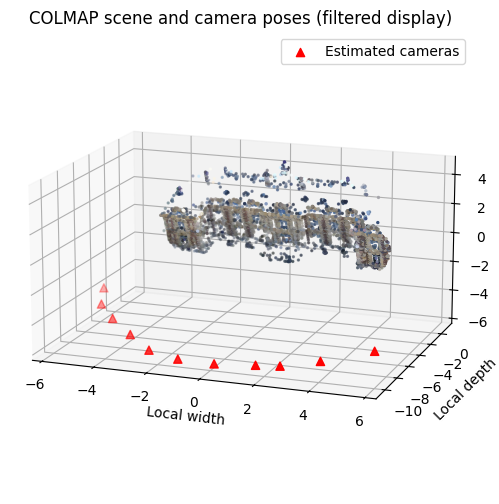

In [ ]:
# Select well-supported points and remove the most distant 5% for display.
selected = [p for p in model.points3D.values() if p.track.length() >= 3 and p.error < 1.5]
points = np.array([p.xyz for p in selected])
colors = np.array([p.color for p in selected]) / 255.0
distance = np.linalg.norm(points - np.median(points, axis=0), axis=1)
keep = distance < np.quantile(distance, 0.95)
points, colors = points[keep], colors[keep]
# Rotate the display coordinate system to face the main facade.
origin = points.mean(axis=0)
_, _, basis = np.linalg.svd(points - origin, full_matrices=False)
local_points = (points - origin) @ basis.T
centers = np.array([image.projection_center() for image in model.images.values()])
local_cameras = (centers - origin) @ basis.T
fig = plt.figure(figsize=(9, 6))
ax = fig.add_subplot(111, projection="3d")
ax.scatter(local_points[:,0], local_points[:,2], -local_points[:,1], c=colors, s=2)
ax.scatter(local_cameras[:,0], local_cameras[:,2], -local_cameras[:,1],
           c="red", marker="^", s=35, label="Estimated cameras")
ax.set(xlabel="Local width", ylabel="Local depth", zlabel="Local height",
       title="COLMAP scene and camera poses (filtered display)")
ax.set_box_aspect((2, 1.5, 1))
ax.view_init(elev=15, azim=-70)
ax.legend()
plt.show()

### Construct and save a coarse facade mesh
The filtered display removes the most distant 5% of well-supported points; the full sparse cloud is saved separately. The castle's front is approximately planar. Project its recovered 3D points onto their two main directions, triangulate in that plane, then retain the original 3D coordinates for the mesh vertices. Remove triangles with long edges to reduce bridging of gaps.

This simple 2.5D method is suitable for the main facade, not a full closed object. It may connect unrelated points or miss hidden surfaces. The optional dense COLMAP workflow below gives a more complete surface.

Mesh vertices: 5007 | triangles: 8125
Saved point cloud and mesh to: lab07_results/colmap


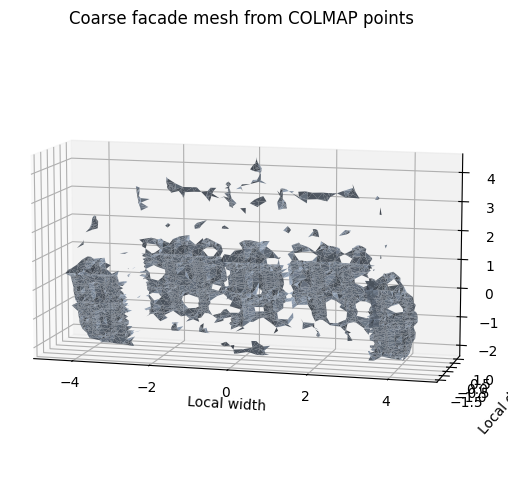

In [ ]:
from scipy.spatial import Delaunay

# Use the same filtered scene points and display basis as above.
vertices = points.copy()
plane_points = local_points[:, :2]
faces = Delaunay(plane_points).simplices
triangles = vertices[faces]
edge_lengths = np.linalg.norm(triangles - np.roll(triangles, 1, axis=1), axis=2)
# Discard unusually large triangles; this is a simple visualization heuristic.
faces = faces[edge_lengths.max(axis=1) < 3 * np.median(edge_lengths)]
mesh_path = colmap_dir / "coarse_mesh.ply"
with open(mesh_path, "w") as f:
    f.write("ply\nformat ascii 1.0\n")
    f.write(f"element vertex {len(vertices)}\n")
    f.write("property float x\nproperty float y\nproperty float z\n")
    f.write(f"element face {len(faces)}\n")
    f.write("property list uchar int vertex_indices\nend_header\n")
    for x, y, z in vertices:
        f.write(f"{x} {y} {z}\n")
    for a, b, c in faces:
        f.write(f"3 {a} {b} {c}\n")
print("Mesh vertices:", len(vertices), "| triangles:", len(faces))
print("Saved point cloud and mesh to:", colmap_dir)
assert len(vertices) > 0 and len(faces) > 0
fig = plt.figure(figsize=(9, 6))
ax = fig.add_subplot(111, projection="3d")
ax.plot_trisurf(local_points[:,0], local_points[:,2], -local_points[:,1], triangles=faces,
                color="lightsteelblue", linewidth=0, alpha=0.95)
ax.set(xlabel="Local width", ylabel="Local depth", zlabel="Local height",
       title="Coarse facade mesh from COLMAP points")
ax.set_box_aspect((2, 0.6, 1))
ax.view_init(elev=10, azim=-75)
plt.show()